# PayWatch: the XGBoost model, calibration and tiers

Trains three seeds from scratch on the TRAIN split only with the production settings, so every threshold and calibration map below comes from validation scores of models that never trained on validation rows. Test is only read for the reported numbers. The shipped production model was refit on train + validation, so it is compared on test only and is not used to pick thresholds here.

In [1]:
import glob, json, os, re, shutil, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve
warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 140)
T0 = time.time()
DEVICE = "cuda" if shutil.which("nvidia-smi") else "cpu"
find = lambda p: sorted(glob.glob(p, recursive=True))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/upi_fingerprint.py")[0]))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/evasion.py")[0]))
import engineer
from entity_history import BASE_KEYS
RAW = os.path.dirname(find("/kaggle/input/**/train_transaction.csv")[0])
SPEC = json.load(open(find("/kaggle/input/**/prod_compact/serving_spec.json")[0]))
COLS = SPEC["features"]
SHIPPED = find("/kaggle/input/**/prod_compact/xgb_seed*.json")
raw = engineer.load_raw(RAW)
base = engineer.build_base(raw.copy(), lags=(7,), decay_lags=(), velocity=False, key_names=BASE_KEYS)
(tr, va, te), art = engineer.finalize(base, d_mode="anchor", return_artifacts=True)
(X_tr, y_tr, t_tr), (X_va, y_va, t_va), (X_te, y_te, t_te) = tr, va, te
UPI_B = {"amount_vs_7day_avg_ratio", "merchant_category_entropy", "hour_deviation_from_user_mean",
         "days_since_last_large_txn", "is_new_merchant", "is_p2p"}


def family(f):
    if f.startswith("h7_"):
        return "entity fraud history"
    if f.startswith("uid_") or f in UPI_B:
        return "UPI behaviour"
    if f.endswith("_freq"):
        return "frequency encoding"
    if re.fullmatch(r"D\d+", f):
        return "time deltas (D)"
    if re.fullmatch(r"V\d+", f):
        return "Vesta V"
    if f.startswith("id_") or f.startswith("Device"):
        return "identity / device"
    if re.fullmatch(r"[CM]\d+", f):
        return "counts / match flags (C, M)"
    return "raw transaction"


def recall_at_fpr(y, p, f):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.interp(f, fpr, tpr))


def op_threshold(score, y, target, n_min=100):
    order = np.argsort(-score)
    tp = np.cumsum(y[order])
    n = np.arange(1, len(y) + 1)
    ok = np.where((tp / n >= target) & (n >= n_min))[0]
    return float(score[order][ok.max()]) if len(ok) else None


def shipped_boosters():
    out = []
    for p in SHIPPED:
        b = xgb.Booster()
        b.load_model(p)
        out.append(b)
    return out


def ensemble_score(boosters, X):
    d = xgb.DMatrix(pd.DataFrame(np.asarray(X, dtype=np.float32), columns=COLS))
    return np.mean([b.predict(d) for b in boosters], axis=0)


print(f"device: {DEVICE} | pipeline built in {(time.time() - T0) / 60:.1f} min | train {X_tr.shape}, val {X_va.shape}, test {X_te.shape} | compact features: {len(COLS)}")

device: cpu | pipeline built in 1.1 min | train (413378, 452), val (88581, 452), test (88581, 452) | compact features: 120


In [2]:
XGB_PARAMS = dict(max_depth=10, learning_rate=0.0558, subsample=0.935, colsample_bytree=0.678, min_child_weight=1,
                  reg_lambda=1.518, gamma=0.0336, scale_pos_weight=39.3)
TAU_DAYS = 120

## 1. Train three seeds (recency weights, early stopping on validation)

In [3]:
w_tr = np.exp(-(t_tr.max() - t_tr) / (TAU_DAYS * 86400.0))
models = []
for seed in (42, 1, 2):
    m = xgb.XGBClassifier(n_estimators=6000, tree_method="hist", device=DEVICE, eval_metric="aucpr", early_stopping_rounds=60,
                          random_state=seed, n_jobs=-1, **XGB_PARAMS)
    t1 = time.time()
    m.fit(X_tr[COLS], y_tr, sample_weight=w_tr, eval_set=[(X_va[COLS], y_va)], verbose=False)
    models.append(m)
    print(f"seed {seed}: {time.time() - t1:.0f}s, best iteration {m.best_iteration}")
print(f"scale_pos_weight {XGB_PARAMS['scale_pos_weight']} (class weights instead of SMOTE), device {DEVICE}")
pv = [m.predict_proba(X_va[COLS])[:, 1] for m in models]
pt = [m.predict_proba(X_te[COLS])[:, 1] for m in models]
s_va, s_te = np.mean(pv, axis=0), np.mean(pt, axis=0)
ship = shipped_boosters()
ship_te = ensemble_score(ship, X_te[COLS])
rows = []
for name, p in [(f"seed {sd} alone", q) for sd, q in zip((42, 1, 2), pt)] + [("3-seed ensemble (train only)", s_te),
                                                                                ("shipped ensemble (refit on train+val)", ship_te)]:
    rows.append({"model": name, "test_pr_auc": round(float(average_precision_score(y_te, p)), 4), "test_roc_auc": round(float(roc_auc_score(y_te, p)), 4),
                 "recall@0.1%FPR": round(recall_at_fpr(y_te, p, 0.001), 3), "recall@1%FPR": round(recall_at_fpr(y_te, p, 0.01), 3),
                 "recall@5%FPR": round(recall_at_fpr(y_te, p, 0.05), 3)})
res = pd.DataFrame(rows).set_index("model")
display(res)
singles = res.test_pr_auc.iloc[:3]
print(f"single seeds: PR-AUC {singles.min():.3f} to {singles.max():.3f}; train-only ensemble {res.test_pr_auc.iloc[3]:.3f}; "
      f"shipped refit ensemble {res.test_pr_auc.iloc[4]:.3f} (refit adds the validation period as training data)")
print(f"reference: a random scorer has PR-AUC = fraud rate = {y_te.mean():.4f}")

seed 42: 70s, best iteration 265


seed 1: 48s, best iteration 153


seed 2: 50s, best iteration 162
scale_pos_weight 39.3 (class weights instead of SMOTE), device cpu


,test_pr_auc,test_roc_auc,recall@0.1%FPR,recall@1%FPR,recall@5%FPR
model,,,,,
seed 42 alone,0.6636,0.9354,0.316,0.604,0.733
seed 1 alone,0.6567,0.9389,0.313,0.598,0.728
seed 2 alone,0.6588,0.9374,0.320,0.605,0.738
3-seed ensemble (train only),0.6675,0.9405,0.319,0.613,0.736
shipped ensemble (refit on train+val),0.7062,0.9484,0.388,0.637,0.769


single seeds: PR-AUC 0.657 to 0.664; train-only ensemble 0.667; shipped refit ensemble 0.706 (refit adds the validation period as training data)
reference: a random scorer has PR-AUC = fraud rate = 0.0348


## 2. Curves (train-only ensemble versus the shipped refit)

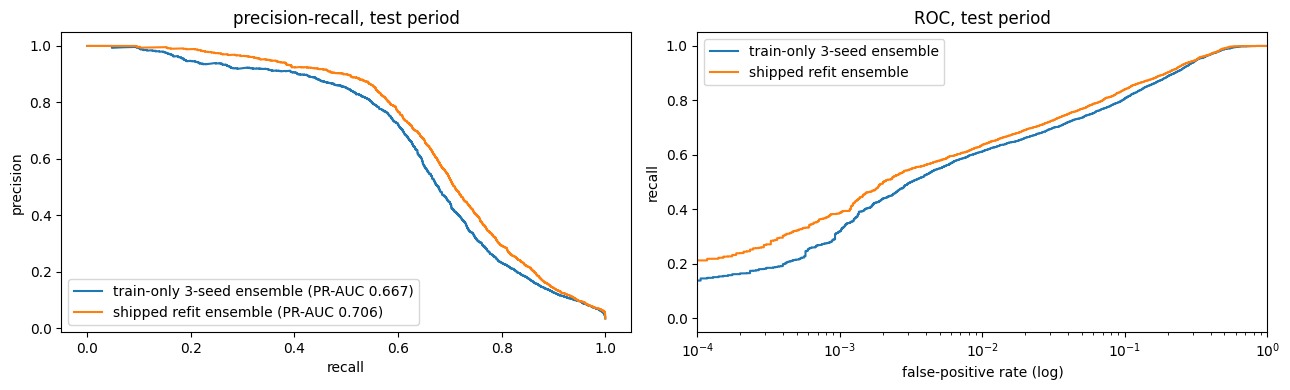

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, p in (("train-only 3-seed ensemble", s_te), ("shipped refit ensemble", ship_te)):
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax[0].plot(rc, pr, label=f"{name} (PR-AUC {average_precision_score(y_te, p):.3f})")
    fpr, tpr, _ = roc_curve(y_te, p)
    ax[1].plot(fpr, tpr, label=name)
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("precision-recall, test period"); ax[0].legend()
ax[1].set_xscale("log"); ax[1].set_xlim(1e-4, 1); ax[1].set_xlabel("false-positive rate (log)"); ax[1].set_ylabel("recall"); ax[1].set_title("ROC, test period"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Calibration (fitted on validation scores of the train-only ensemble)

Raw scores are not probabilities (class weights inflate them). An isotonic map turns them into calibrated probabilities.

Brier score on test: raw 0.0272  ->  calibrated 0.0175


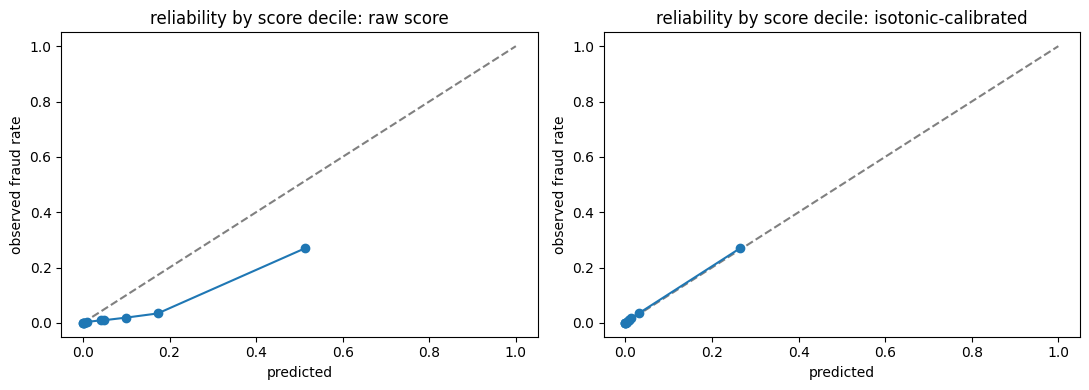

In [5]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss
iso = IsotonicRegression(out_of_bounds="clip").fit(s_va, y_va)
c_te = iso.predict(s_te)
print(f"Brier score on test: raw {brier_score_loss(y_te, s_te):.4f}  ->  calibrated {brier_score_loss(y_te, c_te):.4f}")
bins = pd.qcut(pd.Series(c_te).rank(method="first"), 10, labels=False)
rel = pd.DataFrame({"predicted": pd.Series(c_te).groupby(bins).mean(), "observed": pd.Series(y_te).groupby(bins).mean()})
rel_raw = pd.DataFrame({"predicted": pd.Series(s_te).groupby(bins).mean(), "observed": pd.Series(y_te).groupby(bins).mean()})
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, r, t in ((ax[0], rel_raw, "raw score"), (ax[1], rel, "isotonic-calibrated")):
    a.plot([0, 1], [0, 1], "--", c="grey"); a.plot(r.predicted, r.observed, "o-"); a.set_title(f"reliability by score decile: {t}")
    a.set_xlabel("predicted"); a.set_ylabel("observed fraud rate")
plt.tight_layout(); plt.show()

## 4. Action tiers by precision target (thresholds from validation, applied to test)

Production picks thresholds on the first half of the test period and reports the second half (`models/compact/serving_spec.json`); this notebook uses the simpler validation-to-test protocol.

In [6]:
rows = []
for tier, target in (("SOFT_FLAG", 0.5), ("CHALLENGE", 0.7), ("HARD_BLOCK", 0.9)):
    thr = op_threshold(s_va, y_va, target)
    flag = s_te >= thr
    rows.append({"tier": tier, "val_precision_target": target, "alert_rate_test": round(float(flag.mean()), 4),
                 "test_precision": round(float(y_te[flag].mean()), 3), "test_recall": round(float(flag[y_te == 1].mean()), 3)})
tiers = pd.DataFrame(rows).set_index("tier")
display(tiers)
gap = (tiers.val_precision_target - tiers.test_precision).round(3)
print("target minus achieved test precision per tier:", gap.to_dict())
print("a positive gap means the validation period was easier than the test period; that gap is the honest estimate of what operators will see")

,val_precision_target,alert_rate_test,test_precision,test_recall
tier,,,,
SOFT_FLAG,0.5,0.0493,0.482,0.683
CHALLENGE,0.7,0.0308,0.691,0.612
HARD_BLOCK,0.9,0.0180,0.875,0.453


target minus achieved test precision per tier: {'SOFT_FLAG': 0.018, 'CHALLENGE': 0.009, 'HARD_BLOCK': 0.025}
a positive gap means the validation period was easier than the test period; that gap is the honest estimate of what operators will see


## Reading the results

Everything above is computed: compare the single-seed rows, the train-only ensemble and the shipped refit model in section 1 to see what seed averaging and the extra training period are each worth. Precision of 0.99 on all alerts is not reachable on this data; only the very top slice is that precise (see the README).